# <center> Projeto 02 - Unidade II </center>

Seja o sistema dinâmico dado pela seguinte função não linear:

$$
y[n] = f\left(y[n - 1],\, y[n - 2],\, u[n],\, u[n - 1]\right)
$$

cujo conjunto entrada / saídas é apresentado na tabela *dados.txt*. Implemente um identificador via **Método dos Mínimos Quadrados** e um filtro utilizando **funções no domínio dos complexos**. Em seguida, compare os resultados obtidos utilizando como métricas o **Erro Médio Quadrático** e o **Coeficiente de Correlação de Pearson** (ver Lab 04). Apresente conclusões.

In [58]:
import numpy as np
from numpy.linalg import pinv
import matplotlib.pyplot as plt

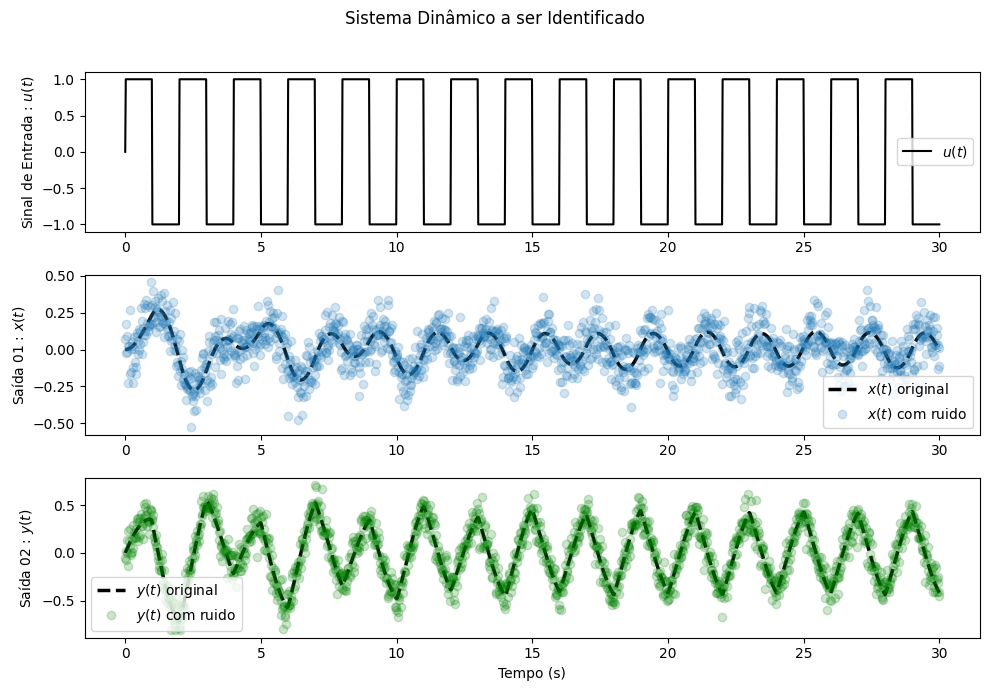

In [59]:
data = np.loadtxt('dados.txt', delimiter=',', skiprows=1)

t = data[:, 0]
u = data[:, 1]
x = data[:, 2]
y = data[:, 3]
x1 = data[:, 4]
y1 = data[:, 5]

# Plot results of simulation
plt.figure(figsize=(10, 7))
plt.subplot(3, 1, 1)
plt.plot(t, u, label='$u(t)$', color='k')
plt.ylabel('Sinal de Entrada : $u(t)$')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(t, x1, '--k', lw = 2.5, label='$x(t)$ original')
plt.plot(t, x, 'o', alpha = 0.2, label='$x(t)$ com ruido')
plt.ylabel('Saída 01 : $x(t)$')
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(t, y1, '--k', lw = 2.5, label='$y(t)$ original')
plt.plot(t, y, 'og', alpha=0.2, label='$y(t)$ com ruido')
plt.xlabel('Tempo (s)')
plt.ylabel('Saída 02 : $y(t)$')
plt.legend()

plt.suptitle('Sistema Dinâmico a ser Identificado')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

EMQ de x: 0.009892
EMQ de y: 0.010480


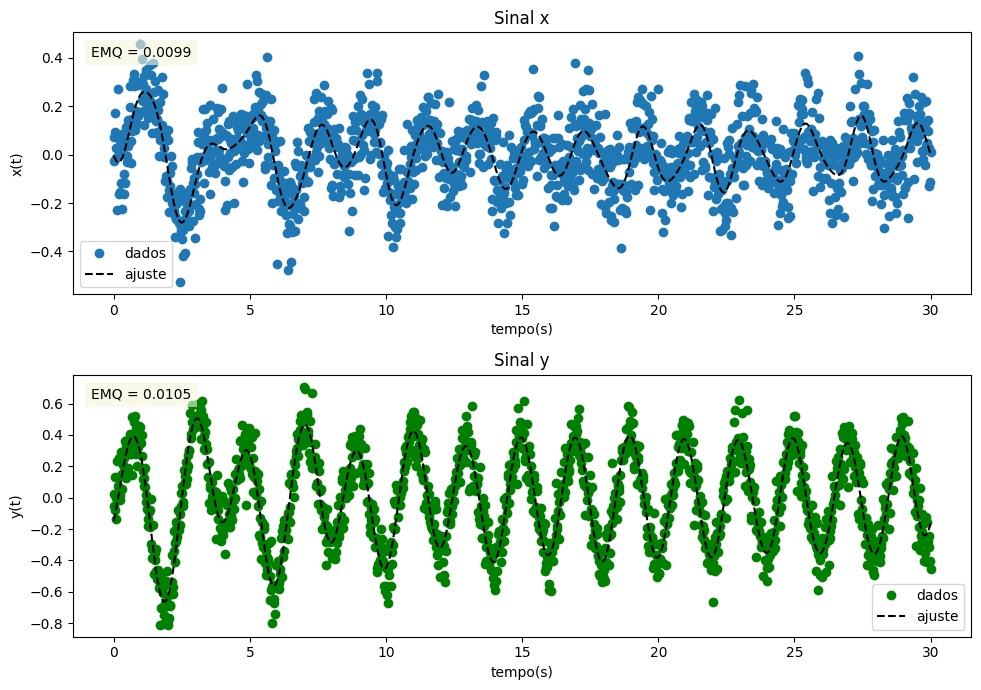

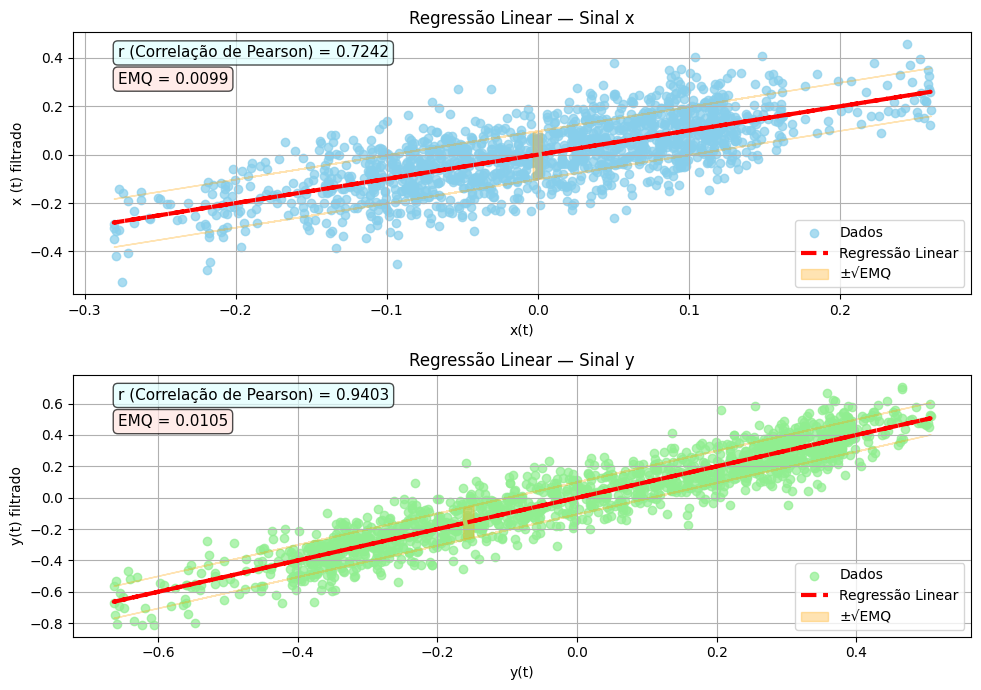

In [67]:
#filtro por funções complexas
from scipy.stats import linregress, pearsonr

data = np.loadtxt('dados.txt', delimiter=',', skiprows=1)

t = data[:, 0]
u = data[:, 1]
x = data[:, 2]
y = data[:, 3]
x1 = data[:, 4]
y1 = data[:, 5]

r = len(u)

# cálculo das matrizes por complexo
g = np.exp(-2j * np.pi / r)
W = np.array([[g**(m*n) for n in range(r)] for m in range(r)]) / np.sqrt(r)
X = W @ x
Y = W @ y

# Definição do filtro complexp

H = np.zeros(r, dtype=complex)
filtro = 30  # filtro escolhido que melhor se ajuste as dados fornecidos;
H[:filtro] = 1
H[-filtro:] = 1

Xf = H * X
Yf = H * Y

# Transformadas inversas
x_filtrado = np.real(W.conj().T @ Xf)
y_filtrado = np.real(W.conj().T @ Yf)

# Cálculo do Erro médio quadrado
EMQ_x = np.mean((x - x_filtrado)**2)
EMQ_y = np.mean((y - y_filtrado)**2)

# respostas dos emq´s

print(f"EMQ de x: {EMQ_x:.6f}")
print(f"EMQ de y: {EMQ_y:.6f}")

# Gráficos filtro sinais x e y
plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, 'o', label='dados')
plt.plot(t, x_filtrado, '--k', label='ajuste')
plt.xlabel('tempo(s)')
plt.ylabel('x(t)')
plt.legend()
plt.title('Sinal x')
plt.text(0.02, 0.95, f'EMQ = {EMQ_x:.4f}', transform=plt.gca().transAxes,fontsize=10, verticalalignment='top',bbox=dict(facecolor='beige', alpha=0.6, edgecolor='none'))

plt.subplot(2, 1, 2)
plt.plot(t, y, 'og', label='dados')
plt.plot(t, y_filtrado, '--k', label='ajuste')
plt.xlabel('tempo(s)')
plt.ylabel('y(t)')
plt.legend()
plt.title('Sinal y')
plt.text(0.02, 0.95, f'EMQ = {EMQ_y:.4f}', transform=plt.gca().transAxes,fontsize=10, verticalalignment='top',bbox=dict(facecolor='beige', alpha=0.6, edgecolor='none'))
plt.tight_layout()
plt.show()

#cálculo do coeficiente de pearson
RMSE_x = np.sqrt(EMQ_x)
RMSE_y = np.sqrt(EMQ_y)

# Regressão linear x
a_x, b_x, r_val_x, p_val_x, std_err_x = linregress(x_filtrado, x)
corr_x, _ = pearsonr(x_filtrado, x)
y_reg_x = a_x * x_filtrado + b_x

# Regressão linear y
a_y, b_y, r_val_y, p_val_y, std_err_y = linregress(y_filtrado, y)
corr_y, _ = pearsonr(y_filtrado, y)
y_reg_y = a_y * y_filtrado + b_y

plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.scatter(x_filtrado, x, alpha=0.7, label='Dados', color='skyblue')
plt.plot(x_filtrado, y_reg_x, '--r', lw=3.0, label='Regressão Linear')
plt.fill_between(x_filtrado, y_reg_x - RMSE_x, y_reg_x + RMSE_x,color='orange', alpha=0.3, label='±√EMQ')

reg_eq_x = f"x = {a_x:.4f} * x_filtrado + {b_x:.4f}"
corr_text_x = f"r (Correlação de Pearson) = {corr_x:.4f}"
emq_text_x = f"EMQ = {EMQ_x:.4f}"

plt.text(0.05, 0.95, corr_text_x, transform=plt.gca().transAxes,fontsize=11, verticalalignment='top',bbox=dict(boxstyle="round", facecolor='lightcyan', alpha=0.7))
plt.text(0.05, 0.85, emq_text_x, transform=plt.gca().transAxes,fontsize=11, verticalalignment='top',bbox=dict(boxstyle="round", facecolor='mistyrose', alpha=0.7))

plt.title('Regressão Linear — Sinal x')
plt.xlabel('x(t)')
plt.ylabel('x (t) filtrado')
plt.legend()
plt.grid()

# gráfico da regressão y

plt.subplot(2, 1, 2)
plt.scatter(y_filtrado, y, alpha=0.7, label='Dados', color='lightgreen')
plt.plot(y_filtrado, y_reg_y, '--r', lw=3.0, label='Regressão Linear')
plt.fill_between(y_filtrado, y_reg_y - RMSE_y, y_reg_y + RMSE_y,color='orange', alpha=0.3, label='±√EMQ')

reg_eq_y = f"y = {a_y:.4f} * y_filtrado + {b_y:.4f}"
corr_text_y = f"r (Correlação de Pearson) = {corr_y:.4f}"
emq_text_y = f"EMQ = {EMQ_y:.4f}"

plt.text(0.05, 0.95, corr_text_y, transform=plt.gca().transAxes,fontsize=11, verticalalignment='top',bbox=dict(boxstyle="round", facecolor='lightcyan', alpha=0.7))
plt.text(0.05, 0.85, emq_text_y, transform=plt.gca().transAxes,fontsize=11, verticalalignment='top',bbox=dict(boxstyle="round", facecolor='mistyrose', alpha=0.7))

plt.title('Regressão Linear — Sinal y')
plt.xlabel('y(t)')
plt.ylabel('y(t) filtrado')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

EMQ_x = 0.013109, EMQ_y = 0.015455


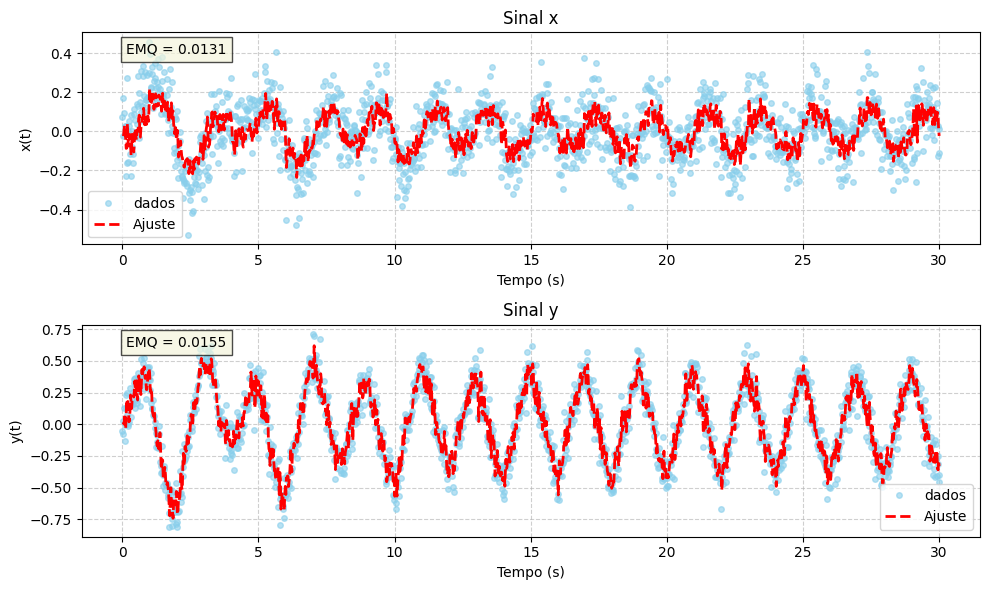

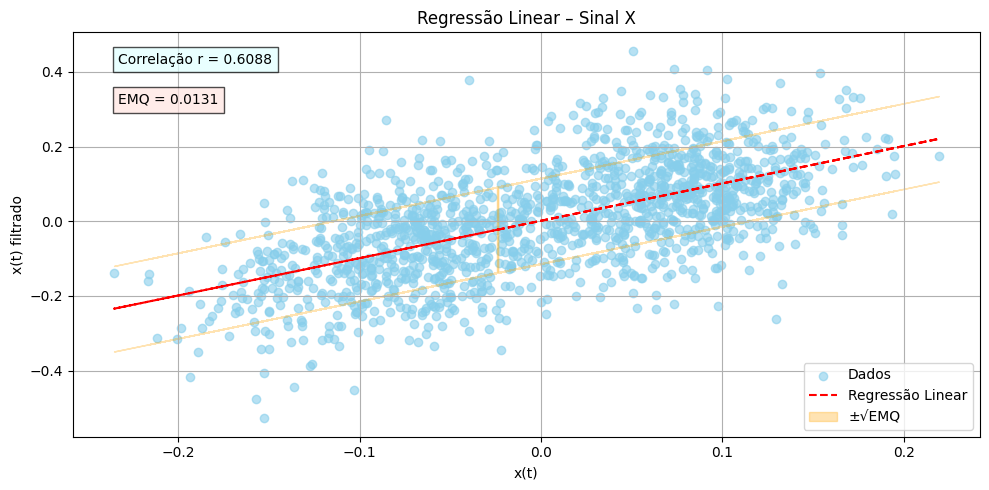

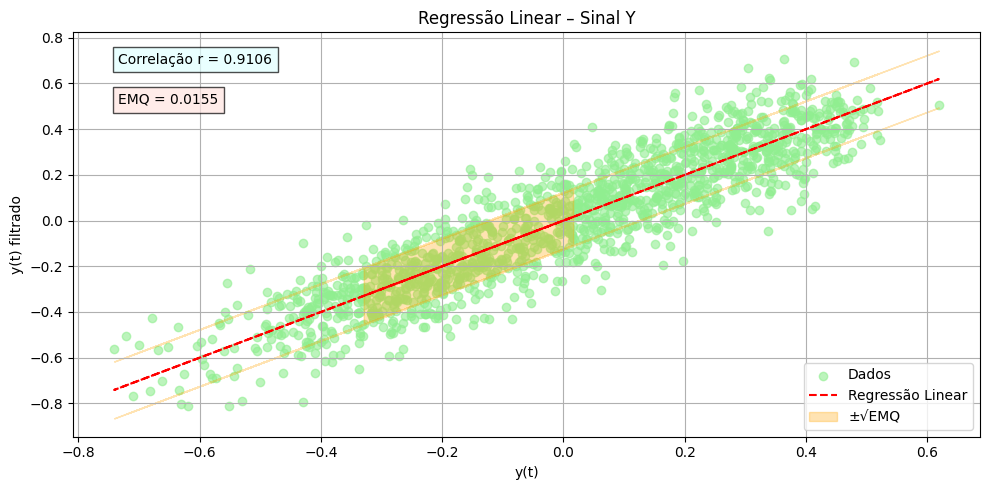

In [68]:
# Repetição do processo para o ajuste via MMQ
from scipy.stats import linregress, pearsonr
from numpy.linalg import pinv

data = np.loadtxt('dados.txt', delimiter=',', skiprows=1)

t = data[:, 0]
u = data[:, 1]
x = data[:, 2]
y = data[:, 3]
x1 = data[:, 4]
y1 = data[:, 5]

indice_inicio = 2 # confirma o início do cálculo no índice [2], pois aproveitao o cálculo dos índices [0] e [1]

u_n0 = u[indice_inicio:]
u_n1 = u[indice_inicio-1 : len(u)-1]

x_n1 = x[indice_inicio-1 : len(x)-1]
x_n2 = x[indice_inicio-2 : len(x)-2]

Y_x = x[indice_inicio:]

#transforma os vetores em colunas para formar a matriz phi
Phi_x = np.stack((x_n1, x_n2, u_n0, u_n1), axis=1)

theta_x = pinv(Phi_x) @ Y_x
x_estimado = Phi_x @ theta_x
Y_y = y[indice_inicio:]
y_n1 = y[indice_inicio-1:-1]
y_n2 = y[indice_inicio-2:-2]

Phi_y = np.stack((y_n1, y_n2, u_n0, u_n1), axis=1)

theta_y = pinv(Phi_y) @ Y_y
y_estimado = Phi_y @ theta_y

# Cálculo EMQ
EMQ_x = np.mean((Y_x - x_estimado)**2)
EMQ_y = np.mean((Y_y - y_estimado)**2)

print(f"EMQ_x = {EMQ_x:.6f}, EMQ_y = {EMQ_y:.6f}")

t_estimado = t[indice_inicio:]

#gráficos MMQ

plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(t, x, 'o', color='skyblue', markersize=4, alpha=0.6,label='dados')
plt.plot(t_estimado, x_estimado, 'r--', lw=2, label='Ajuste')
plt.text(0.05, 0.95,f"EMQ = {EMQ_x:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='beige', alpha=0.7))
plt.title("Sinal x")
plt.xlabel('Tempo (s)')
plt.ylabel('x(t)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(2, 1, 2)
plt.plot(t, y, 'o', color='skyblue', markersize=4, alpha=0.6,label='dados')
plt.plot(t_estimado, y_estimado, 'r--', lw=2, label='Ajuste')
plt.text(0.05, 0.95,f"EMQ = {EMQ_y:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='beige', alpha=0.7))
plt.title("Sinal y")
plt.xlabel('Tempo (s)')
plt.ylabel('y(t)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#cálculo da regressão linear de x

x_real_reg = Y_x
x_est_reg = x_estimado

a_x, b_x, r_x, p_x, stderr_x = linregress(x_est_reg, x_real_reg)
x_reg_line = a_x * x_est_reg + b_x

EMQ_x = np.mean((x_real_reg - x_est_reg)**2)
RMSE_x = np.sqrt(EMQ_x)

#gráfico regressão x
plt.figure(figsize=(10, 5))
plt.scatter(x_est_reg, x_real_reg, color='skyblue', alpha=0.6,label='Dados')
plt.plot(x_est_reg, x_reg_line, '--r', label='Regressão Linear')

plt.fill_between(x_est_reg, x_reg_line - RMSE_x, x_reg_line + RMSE_x,color='orange', alpha=0.3, label='±√EMQ')

plt.title("Regressão Linear – Sinal X")
plt.xlabel("x(t)")
plt.ylabel("x(t) filtrado")
plt.legend()
plt.grid()

plt.text(0.05, 0.95,f"Correlação r = {r_x:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='lightcyan', alpha=0.7))
plt.text(0.05, 0.85,f"EMQ = {EMQ_x:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='mistyrose', alpha=0.7))

plt.tight_layout()
plt.show()

#cálculo da regressão y

y_real_reg = Y_y
y_est_reg = y_estimado

a_y, b_y, r_y, p_y, stderr_y = linregress(y_est_reg, y_real_reg)
y_reg_line = a_y * y_est_reg + b_y

EMQ_y = np.mean((y_real_reg - y_est_reg)**2)
RMSE_y = np.sqrt(EMQ_y)

#gráfico da regressão y

plt.figure(figsize=(10, 5))
plt.scatter(y_est_reg, y_real_reg, color='lightgreen', alpha=0.6,label='Dados')
plt.plot(y_est_reg, y_reg_line, '--r', label='Regressão Linear')

plt.fill_between(y_est_reg, y_reg_line - RMSE_y, y_reg_line + RMSE_y,color='orange', alpha=0.3, label='±√EMQ')

plt.title("Regressão Linear – Sinal Y")
plt.xlabel("y(t)")
plt.ylabel("y(t) filtrado")
plt.legend()
plt.grid()

plt.text(0.05, 0.95,f"Correlação r = {r_y:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='lightcyan', alpha=0.7))
plt.text(0.05, 0.85,f"EMQ = {EMQ_y:.4f}",transform=plt.gca().transAxes,va='top',fontsize=10,bbox=dict(facecolor='mistyrose', alpha=0.7))

plt.tight_layout()
plt.show()

In [65]:
# CONCLUSÃO:
""" Diante dos cálculos feitos e das observações dos gráficos plotados, pode-se perceber que o método do filtro possui um EMQ menor em ambos os casos (x e y) quando comparado ao método dos
mínimos quadrados. Além disso, outra importante métrica observada foi o coeficiente de pearson. O coeficiente calculado utilizando as funções no domínio dos complexos foi maior que o
coeficiente calculado utilizando o método dos mínimos quadrados.
Dados dos resultados:
Filtro:
  EMQ_x = 0,0099
  EMQ_y = 0,0105
  r_x = 0,7242
  r_y = 0,9403

MMQ:
  EMQ_x = 0,0131
  EMQ_y = 0,0155
  r_x = 0,6088
  r_y = 0,9106

Ou seja, diante da análise de todos esses dados e da visualização dos gráficos, podemos concluir que o método do filtro é mais eficiente e consegue se adequar à curva dos dados fornecidos

"""

' Diante dos cálculos feitos e das observações dos gráficos plotados, pode-se perceber que o método do filtro possui um EMQ menor em ambos os casos (x e y) quando comparado ao método dos\nmínimos quadrados. Além disso, outra importante métrica observada foi o coeficiente de pearson. O coeficiente calculado utilizando as funções no domínio dos complexos foi maior que o\ncoeficiente calculado utilizando o método dos mínimos quadrados. \nDados dos resultados:\n\nOutra ponto importante é a análise dos gráficos,\n\n\nOu seja, diante da análise de todos esses dados e das análises acerca \n\n\n'